# 02 – Wybór modelu: walidacja krzyżowa szeregów czasowych

**Cel:** porównać modele-kandydatów uczciwie, na wielu okresach, i wybrać jeden do dalszej pracy.

## Metodologia

**1. Holdout.** Dane od `HOLDOUT_START` (1.09.2026) są odłożone i **nie są tu używane**.
Posłużą do jednej, końcowej oceny wybranego modelu. Jeśli wybieralibyśmy model na tych samych danych,
na których go potem oceniamy, wynik byłby zbyt optymistyczny.

**2. Walidacja krzyżowa expanding window (walk-forward).** Każdy miesiąc od lipca 2025 do sierpnia 2026
(14 foldów) jest raz zbiorem testowym. Model uczy się na **wszystkim, co było wcześniej**:

```
fold 2025-07:  [trening: 06.2024 – 06.2025]  [test: 07.2025]
fold 2025-08:  [trening: 06.2024 – 07.2025]  [test: 08.2025]
...
fold 2026-08:  [trening: 06.2024 – 07.2026]  [test: 08.2026]   | holdout: 09.2026 → (nie dotykamy)
```

Dlaczego nie zwykła k-krotna CV z losowym podziałem? Model uczyłby się wtedy na przyszłości (np. lutym)
i był sprawdzany na przeszłości (styczniu), a takiej sytuacji nigdy nie ma w produkcji. Douczanie co miesiąc
odpowiada też temu, jak model działałby w praktyce.

**3. Metryki.** Główna to **MAE** [MW], czyli średni błąd bezwzględny. Pomocnicze: RMSE (mocniej karze duże
pomyłki) i **bias** = rzeczywiste − prognoza (plus oznacza, że model **zaniża**). Prognozę PSE oceniamy na
dokładnie tych samych godzinach.

**4. Uczciwość.** Pogoda w cechach to pogoda **faktyczna**. PSE w chwili prognozy znało tylko **prognozę**
pogody, więc nasze wyniki są na razie zawyżone na naszą korzyść.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from kse_forecast.config import FEATURES_PATH, TARGET
from kse_forecast.evaluation import PSE_NAME, cross_validate, fold_mae, summarize
from kse_forecast.features import ALL_FEATURES
from kse_forecast.models import CANDIDATES, make_lgbm
from kse_forecast.validation import monthly_folds, split_holdout

plt.rcParams.update(
    {
        "figure.figsize": (12, 4),
        "figure.dpi": 100,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "lines.linewidth": 1.5,
        "font.size": 10,
    }
)
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8c8c8c"

features = pd.read_parquet(FEATURES_PATH)
dev, holdout = split_holdout(features)
folds = monthly_folds()
print(f"Dane deweloperskie: {dev.index.min()} -> {dev.index.max()} ({len(dev)} h)")
print(f"Holdout (nieużywany): od {holdout.index.min()} ({len(holdout)} h)")
print(f"Foldy CV: {len(folds)}, od {folds[0].name} do {folds[-1].name}")

Dane deweloperskie: 2024-06-22 21:00:00+00:00 -> 2026-08-31 21:00:00+00:00 (19201 h)
Holdout (nieużywany): od 2026-08-31 22:00:00+00:00 (1993 h)
Foldy CV: 14, od 2025-07 do 2026-08


## 1. Kandydaci

Od najprostszego do najbardziej złożonego. Model naiwny i regresja liniowa to punkty odniesienia:
złożony model ma sens tylko wtedy, gdy wyraźnie je pobija.

In [2]:
pd.DataFrame(
    [(c.name, c.description, len(c.features)) for c in CANDIDATES], columns=["model", "opis", "liczba cech"]
).set_index("model")

,opis,liczba cech
model,,
naive_week,"Naiwny: tyle, co o tej samej godzinie tydzień ...",1
ridge,"Regresja liniowa (Ridge), kalendarz jako one-hot",18
lgbm_base,"LightGBM, cechy z pierwszej wersji (bez dni mo...",16
lgbm,LightGBM + dni mostowe i okres świąteczny,18
lgbm_ratio,"LightGBM, cel względny: load / load_mean_7d",18
lgbm_linear_tree,LightGBM z liniowymi liśćmi (umie ekstrapolowa...,18
ensemble,Średnia z lgbm_ratio i lgbm_linear_tree,18


## 2. Wyniki walidacji krzyżowej

Każdy kandydat jest trenowany od nowa w każdym z 14 foldów. Trwa to kilka minut.

In [3]:
predictions = cross_validate(dev, CANDIDATES, folds)
summary = summarize(predictions)
summary

,mae,rmse,bias,mae_fold_std,folds_better_than_pse
model,,,,,
pse,433.1,574.5,-156.7,70.7,0
ensemble,495.8,674.1,107.6,139.8,6
lgbm_linear_tree,531.4,718.2,141.9,180.6,3
lgbm_ratio,533.3,741.7,73.4,189.1,4
lgbm,534.7,750.0,130.0,177.1,2
lgbm_base,548.3,766.4,109.1,181.4,2
ridge,665.7,880.7,163.1,138.7,1
naive_week,990.4,1474.1,4.6,354.4,0


**Jak czytać tabelę:** `mae_fold_std` to rozrzut MAE między miesiącami (czy model jest stabilny),
a `folds_better_than_pse` to liczba miesięcy (na 14), w których model pobił PSE.

**Wniosek:**
- **Żaden model nie pobija PSE.** Najlepszy, `ensemble`, ma MAE ok. **496 MW** wobec ok. **433 MW** PSE,
  czyli myli się średnio o ok. 15% więcej.
- Złożoność się opłaca: LightGBM (ok. 530–550 MW) wyraźnie bije regresję liniową (ok. 666 MW),
  a ta jest o połowę lepsza od modelu naiwnego (ok. 990 MW).
- **Dni mostowe i okres świąteczny** (`lgbm` wobec `lgbm_base`) obniżają MAE o ok. 14 MW. Na całym okresie
  to niewiele, ale te dni są rzadkie, więc efekt sprawdzimy osobno w sekcji 5.
- Nasze modele mają **plus w biasie**, czyli **zaniżają**, a PSE zawyża.
- PSE jest dużo **stabilniejsze** (rozrzut ok. 70 MW wobec 140–190 MW), bo nasze modele mają bardzo słabe miesiące.
- `ensemble` jest lepszy od obu swoich składników, bo mylą się one w różnych miejscach, więc błędy częściowo się znoszą.
  Pobija PSE w 6 z 14 miesięcy.

## 3. Błąd w kolejnych miesiącach

Pokazujemy trzy serie: PSE, najlepszy model (`ensemble`) i regresję liniową jako punkt odniesienia.

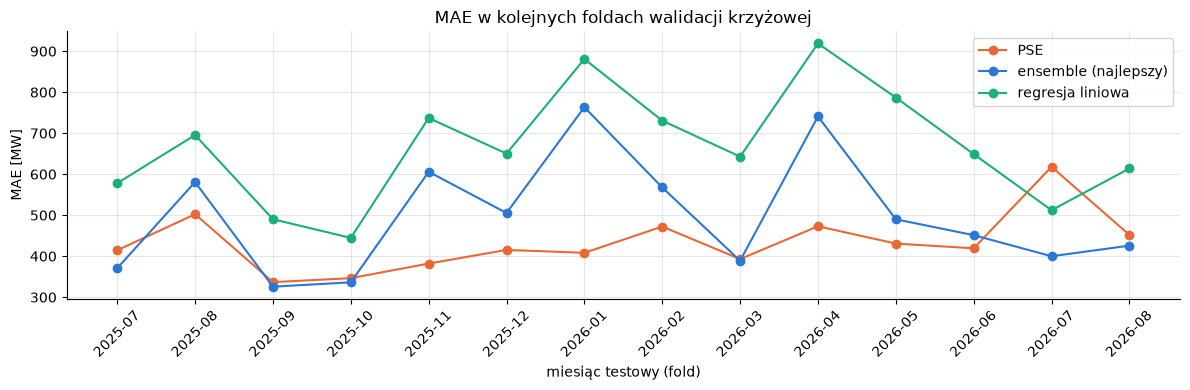

model,ensemble,lgbm,lgbm_base,lgbm_linear_tree,lgbm_ratio,naive_week,pse,ridge
fold,,,,,,,,
2025-07,371.0,366.0,375.0,416.0,345.0,506.0,414.0,578.0
2025-08,581.0,583.0,566.0,605.0,577.0,696.0,502.0,695.0
2025-09,326.0,357.0,361.0,332.0,333.0,512.0,337.0,490.0
2025-10,336.0,392.0,390.0,364.0,343.0,666.0,346.0,445.0
2025-11,606.0,653.0,703.0,579.0,688.0,1293.0,382.0,737.0
2025-12,505.0,536.0,608.0,566.0,538.0,1248.0,415.0,650.0
2026-01,763.0,1031.0,1046.0,1016.0,984.0,1660.0,408.0,881.0
2026-02,568.0,647.0,634.0,503.0,727.0,1408.0,472.0,731.0
2026-03,389.0,442.0,440.0,417.0,418.0,846.0,393.0,643.0


In [4]:
per_fold = fold_mae(predictions)
fig, ax = plt.subplots(figsize=(12, 4))
for model, color, label in [
    (PSE_NAME, ORANGE, "PSE"),
    ("ensemble", BLUE, "ensemble (najlepszy)"),
    ("ridge", AQUA, "regresja liniowa"),
]:
    ax.plot(per_fold.index, per_fold[model], marker="o", markersize=6, color=color, label=label)
ax.set_ylabel("MAE [MW]")
ax.set_xlabel("miesiąc testowy (fold)")
ax.set_title("MAE w kolejnych foldach walidacji krzyżowej")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
per_fold.round(0)

**Wniosek:**
- W lipcu, wrześniu i październiku 2025 oraz w marcu, lipcu i sierpniu 2026 `ensemble` **bije PSE**.
  Najwyraźniej w lipcu 2026 (ok. 400 wobec ok. 620 MW): PSE miało wtedy duży błąd, zawyżało o ok. 500 MW,
  co widzieliśmy w EDA.
- **Styczeń 2026 to najsłabszy miesiąc:** `ensemble` ok. 760 MW, pojedyncze modele LightGBM ok. 1000 MW,
  a PSE ok. 400 MW. To ta mroźna zima, której model nie widział w danych treningowych (EDA, sekcja 5).
- Kwiecień 2026 też jest słaby (ok. 700 MW). Możliwy powód to Wielkanoc (święta ruchome, mało przykładów)
  i szybka zmiana temperatury wiosną.

## 4. Zima i mróz: czy modele liniowe pomagają?

EDA pokazała, że zapotrzebowanie rośnie liniowo z zimnem, a zwykłe drzewa nie umieją ekstrapolować.
Sprawdzamy to wprost: MAE i bias w miesiącach zimowych oraz w godzinach z mrozem poniżej −5 °C.

In [5]:
analysis = predictions.join(
    dev[["month", "hour", "temperature_2m", "is_holiday", "is_bridge_day", "is_christmas_period"]]
)
analysis["abs_error"] = (analysis["y_true"] - analysis["y_pred"]).abs()
analysis["error"] = analysis["y_true"] - analysis["y_pred"]

models = [PSE_NAME, "ensemble", "lgbm_ratio", "lgbm_linear_tree", "lgbm", "ridge"]
winter = analysis["month"].isin([12, 1, 2])
frost = analysis["temperature_2m"] < -5
table = (
    pd.DataFrame(
        {
            "MAE zima (XII–II)": analysis[winter].groupby("model")["abs_error"].mean(),
            "MAE reszta roku": analysis[~winter].groupby("model")["abs_error"].mean(),
            "MAE mróz < −5 °C": analysis[frost].groupby("model")["abs_error"].mean(),
            "bias mróz < −5 °C": analysis[frost].groupby("model")["error"].mean(),
        }
    )
    .loc[models]
    .round(0)
)
print("Godzin z mrozem < −5 °C w foldach testowych:", frost[analysis["model"] == PSE_NAME].sum())
table

Godzin z mrozem < −5 °C w foldach testowych: 513


,MAE zima (XII–II),MAE reszta roku,MAE mróz < −5 °C,bias mróz < −5 °C
model,,,,
pse,431.0,434.0,423.0,39.0
ensemble,614.0,464.0,876.0,727.0
lgbm_ratio,751.0,475.0,1083.0,828.0
lgbm_linear_tree,701.0,486.0,912.0,626.0
lgbm,741.0,480.0,1165.0,1058.0
ridge,755.0,642.0,964.0,585.0


**Wniosek:**
- Poza zimą `ensemble` jest już blisko PSE (ok. 464 wobec 434 MW, różnica ok. 30 MW).
  W zimie różnica to ok. 180 MW. Choć zima to tylko 3 z 14 foldów, odpowiada za ok. 60% całej przewagi PSE.
- Przy mrozie poniżej −5 °C modele z elementem liniowym (`lgbm_linear_tree`, `ridge`) mają wyraźnie mniejszy
  błąd niż zwykłe drzewa (`lgbm`). To potwierdza hipotezę z EDA o ekstrapolacji.
- Ale nawet one mają przy mrozie bias ok. +600 MW, czyli nadal mocno **zaniżają**. PSE nie ma tego problemu
  (bias bliski zera). Linear trees to krok w dobrą stronę, a nie rozwiązanie.
- `ensemble` łączy `lgbm_ratio` (dobry w typowe dni) z `lgbm_linear_tree` (lepszy przy mrozie), dlatego ma
  najlepszy wynik w zimie spośród naszych modeli (ok. 614 MW).

## 5. Dni nietypowe: czy nowe cechy z EDA działają?

Porównujemy `lgbm_base` (bez cech `is_bridge_day` i `is_christmas_period`) z `lgbm` (z nimi).
To ten sam model i te same parametry, różnią się tylko cechy, więc różnica w błędzie to efekt nowych cech.

In [6]:
special = (
    pd.DataFrame(
        {
            "dni mostowe": analysis[analysis["is_bridge_day"] == 1].groupby("model")["abs_error"].mean(),
            "okres 24.12–6.01": analysis[analysis["is_christmas_period"] == 1]
            .groupby("model")["abs_error"]
            .mean(),
            "święta": analysis[analysis["is_holiday"] == 1].groupby("model")["abs_error"].mean(),
        }
    )
    .loc[[PSE_NAME, "ensemble", "lgbm", "lgbm_base"]]
    .round(0)
)
print(
    "Dni mostowych w foldach testowych:",
    analysis.loc[(analysis["model"] == PSE_NAME) & (analysis["is_bridge_day"] == 1)].shape[0] // 24,
)
special

Dni mostowych w foldach testowych: 4


,dni mostowe,okres 24.12–6.01,święta
model,,,
pse,484.0,546.0,530.0
ensemble,1268.0,828.0,992.0
lgbm,882.0,822.0,891.0
lgbm_base,1654.0,927.0,880.0


**Wniosek:** cecha `is_bridge_day` **prawie o połowę** obniża błąd w dni mostowe (z ok. 1650 do ok. 880 MW),
a `is_christmas_period` obniża go w okresie świątecznym o ok. 100 MW. To potwierdza wniosek z EDA, że dla
zużycia prądu liczy się to, czy ludzie pracują, a nie formalny status dnia.

Uwaga: w foldach testowych są tylko 4 dni mostowe, więc to sygnał, a nie twardy dowód.

**Ważny kompromis:** `ensemble` jest w dni mostowe wyraźnie **gorszy** niż zwykły `lgbm` (ok. 1270 wobec ok. 880 MW),
a w święta też (ok. 990 wobec ok. 890 MW). Jego składniki gorzej radzą sobie z rzadkimi dniami: cel względny
(`lgbm_ratio`) przenosi poziom z ostatnich 7 dni, a liniowe liście ekstrapolują tam, gdzie nie powinny.
Wybieramy `ensemble`, bo dni nietypowych jest kilkanaście w roku, a zima trwa trzy miesiące. To jednak jasna
wskazówka na przyszłość: dni nietypowe warto obsłużyć osobno (np. korektą albo osobnym modelem).
W dni nietypowe wszystkie nasze modele mylą się 1,5–2,5 razy bardziej niż PSE.

## 6. Błąd w ciągu doby

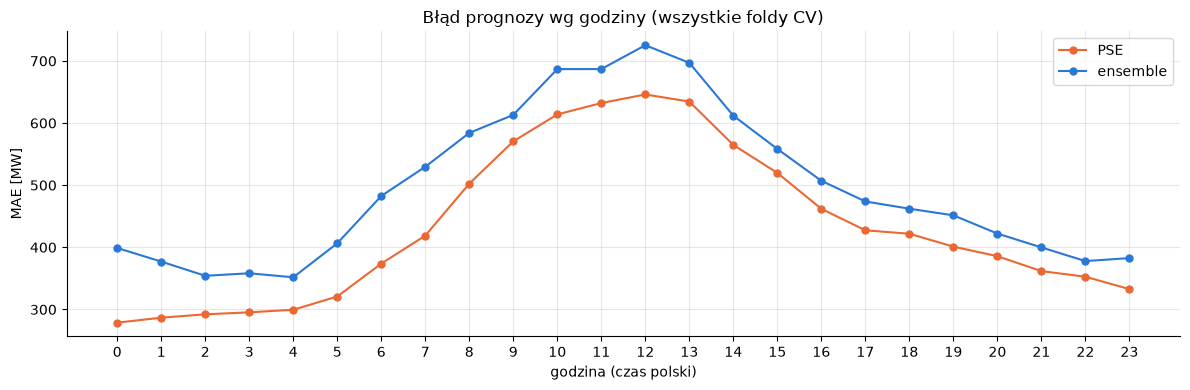

In [7]:
by_hour = analysis[analysis["model"].isin([PSE_NAME, "ensemble"])].pivot_table(
    index="hour", columns="model", values="abs_error"
)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(by_hour.index, by_hour[PSE_NAME], marker="o", markersize=5, color=ORANGE, label="PSE")
ax.plot(by_hour.index, by_hour["ensemble"], marker="o", markersize=5, color=BLUE, label="ensemble")
ax.set_xticks(range(0, 24))
ax.set_xlabel("godzina (czas polski)")
ax.set_ylabel("MAE [MW]")
ax.set_title("Błąd prognozy wg godziny (wszystkie foldy CV)")
ax.legend()
plt.tight_layout()
plt.show()

**Wniosek:**
- Oba modele mylą się najbardziej w środku dnia (10:00–14:00), bo wtedy na zapotrzebowanie wpływa
  fotowoltaika, czyli zachmurzenie (EDA, sekcja 8).
- **Największa różnica względem PSE jest w nocy i wczesnym rankiem** (0:00–7:00, ok. 100 MW), choć to godziny
  najłatwiejsze do przewidzenia. Prawdopodobnie PSE ma informacje, których my nie mamy (np. planowaną pracę
  dużych zakładów przemysłowych albo dane z poprzedniego wieczoru). To dobre miejsce na dalsze poszukiwania.

## 7. Co model uznaje za ważne?

Trenujemy `lgbm` na całym zbiorze deweloperskim i sprawdzamy **gain**, czyli o ile każda cecha łącznie
zmniejszyła błąd w drzewach. To lepsza miara niż liczba użyć cechy (domyślna w LightGBM).

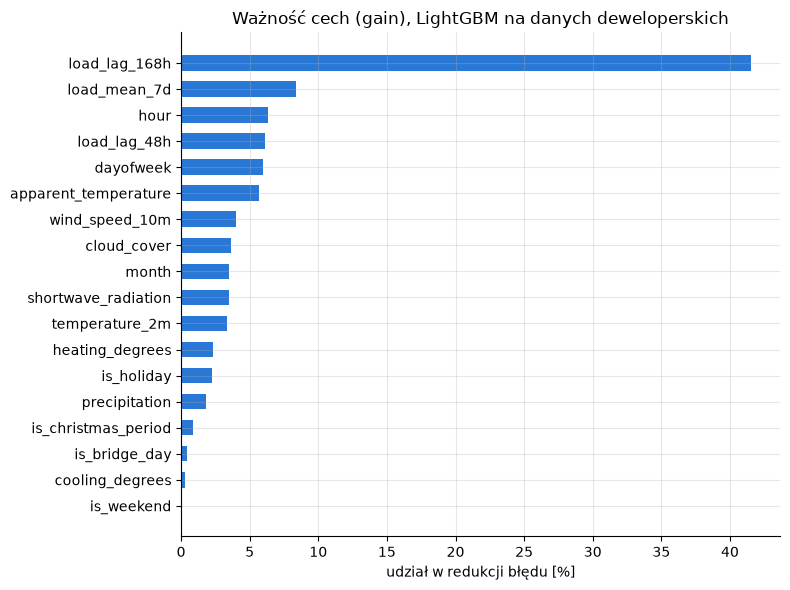

In [8]:
model = make_lgbm().set_params(importance_type="gain").fit(dev[ALL_FEATURES], dev[TARGET])
importance = pd.Series(model.feature_importances_, index=ALL_FEATURES)
importance = (importance / importance.sum() * 100).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(importance.index, importance.values, color=BLUE, height=0.6)
ax.set_xlabel("udział w redukcji błędu [%]")
ax.set_title("Ważność cech (gain), LightGBM na danych deweloperskich")
plt.tight_layout()
plt.show()

**Wniosek:**
- Zdecydowanie dominuje `load_lag_168h` (ok. 40%), czyli „ta sama godzina tydzień temu”. Zgadza się to z EDA
  (najwyższa autokorelacja, sekcja 9).
- Dalej: poziom zapotrzebowania (`load_mean_7d`), kalendarz (`hour`, `dayofweek`) i pogoda.
- Temperatura wydaje się mało ważna, ale to złudzenie: jej wpływ dzieli się między kilka skorelowanych cech
  (`apparent_temperature`, `temperature_2m`, `heating_degrees`), a częściowo jest już zawarty w lagach.
- `is_weekend` ma ważność zero, bo tę samą informację niesie `dayofweek`. `is_bridge_day` i `is_christmas_period`
  mają małą ważność, bo dotyczą kilku dni w roku, ale w te dni realnie pomagają (sekcja 5).

Uwaga: ważność cechy mówi, czego model **używa**, a nie, co **powoduje** zużycie prądu.

## 8. Decyzja i następne kroki

**Wybrany model: `ensemble`** (średnia `lgbm_ratio` i `lgbm_linear_tree`), MAE ok. 496 MW w CV.

**Holdout pozostaje nietknięty.** Ocenimy na nim model dopiero wtedy, gdy zakończymy prace nad cechami
i modelem. Każde „zajrzenie” wcześniej zużywa jego wartość jako niezależnego testu.

**Czego się dowiedzieliśmy:**
1. Ok. 60% przewagi PSE pochodzi z trzech zimowych miesięcy. Poza zimą jesteśmy blisko (ok. 30 MW różnicy).
2. Modele z elementem liniowym lepiej radzą sobie z mrozem, ale nadal mocno zaniżają.
3. Cechy dni nietypowych z EDA realnie pomagają, ale `ensemble` traci część tej korzyści (kompromis z sekcji 5).
4. Największa różnica względem PSE jest w nocy, czyli tam, gdzie zadanie wydaje się najłatwiejsze.

**Następne kroki (w kolejności priorytetu):**
1. **Prognozy pogody zamiast pogody faktycznej** (Open-Meteo Historical Forecast API). Bez tego porównanie
   z PSE jest nieuczciwe na naszą korzyść, więc to warunek wiarygodnego wyniku.
2. **Zima:** cechy lepiej opisujące mróz (np. średnia temperatura z ostatnich 24–72 h, bo budynki stygną
   powoli), mocniejszy model liniowy dla zależności od temperatury.
3. **Dni nietypowe:** Wielkanoc i okres wokół świąt ruchomych.
4. **Strojenie hiperparametrów** w ramach tej samej CV (np. Optuna) i śledzenie eksperymentów (MLflow).